This file contains code to analyze the existing water filling stations on campus, run a weighed scoring method on all potential locations to score locations and make a final prioritized list, as well as code to analyze the new proposed top locations for installing new water filling stations

Parts of this file:


1.   **Initial Impact Analysis:**
Analyzes the effect of existing water filling stations on campus by correlating their locations with campus foot traffic data to assess current utilization and effectiveness.
2.  **Data Integration:**
Merges data from various sources into a comprehensive DataFrame. This integrated dataset now includes all relevant factors (e.g., foot traffic, proximity to other facilities) that influence new installation locations.
3.  **Data Normalization:**
Normalizes the data across different factors to ensure uniformity in scale. This is crucial for the subsequent weighted scoring process, allowing for fair comparisons across diverse data points.
4. **Weighted Scoring and Ranking:**
Assigns weights to each factor based on their importance in determining optimal locations for new installations.
Calculates a score for each potential location using these weights and ranks them accordingly to prioritize locations for new installations.
5.  **Exporting Results:**
The final prioritized list of locations, based on their scores, is saved back to a CSV file for further review or implementation planning.
6.  **Extended Impact Analysis:**
Performs a comparative analysis to predict the potential impact of installing new stations at the top prioritized locations. This includes simulations for different scenarios like installing the top 10, 20, or 30 locations and analyzing the anticipated increase in usage.

# **Importing Data**



In [1]:
# using google collabs
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from itertools import combinations
from scipy.spatial.distance import pdist, squareform
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
# Getting Density Data
density_data = pd.read_csv('/content/drive/MyDrive/ProjectCS506/BU Sustainability: Water Bottle stations/Team B/data/density_data_cleaned.csv')
print('Converted Density Data to density_data dataframe')

# Getting Rooms With Kitchens Data
rooms_with_kitchens = pd.read_csv('/content/drive/MyDrive/ProjectCS506/BU Sustainability: Water Bottle stations/Team B/data/rooms_with_kitchens_cleaned.csv')
print('Converted Rooms With Kitchens Data to density_data dataframe')

# Getting Building List Data
building_list = pd.read_csv('/content/drive/MyDrive/ProjectCS506/BU Sustainability: Water Bottle stations/Team B/data/building_list_cleaned.csv')
print('Converted Building List Data to building_list dataframe')

# Getting High Volume Event Spaces Data
high_volume_event_spaces = pd.read_csv('/content/drive/MyDrive/ProjectCS506/BU Sustainability: Water Bottle stations/Team B/data/high_volume_event_spaces_cleaned.csv')
print('Converted High Volume Event Spaces Data to high_volume_event_spaces dataframe')

# Getting Inventory Existing Stations Data
inventory_existing_stations = pd.read_csv('/content/drive/MyDrive/ProjectCS506/BU Sustainability: Water Bottle stations/Team B/data/inventory_existing_stations_cleaned.csv')
print('Converted Inventory Existing Stations Data to inventory_existing_stations dataframe')

# Getting Distance Data
distance_data = pd.read_csv('/content/drive/MyDrive/ProjectCS506/BU Sustainability: Water Bottle stations/Team B/data/address_distances.csv')
print('Converted Distance Data to distance_data dataframe')

Converted Density Data to density_data dataframe
Converted Rooms With Kitchens Data to density_data dataframe
Converted Building List Data to building_list dataframe
Converted High Volume Event Spaces Data to high_volume_event_spaces dataframe
Converted Inventory Existing Stations Data to inventory_existing_stations dataframe
Converted Distance Data to distance_data dataframe


# **Creating a DataFrame with the average daily density count and the number of existing water filling stations at each location**

In [4]:
density_data.head()

,date,hour,building_type,building_floor,building_desc,density_cnt,capacity,dc_ratio,longitude,latitude,address,full_address
0,2021-03-31,6,Administrative,3,881 commonwealth avenue,2,70,0.03,-71.1153,42.3514,881 commonwealth,881 commonwealth 3
1,2021-03-31,6,Academic,2,808 commonwealth avenue,3,317,0.01,-71.1117,42.3501,808 commonwealth,808 commonwealth 2
2,2021-03-31,6,Academic,3,808 commonwealth avenue,1,185,0.01,-71.1117,42.3501,808 commonwealth,808 commonwealth 3
3,2021-03-31,6,Administrative,1,163-179 amory street,8,103,0.08,-71.1136,42.3502,163-179 amory,163-179 amory 1
4,2021-03-31,6,Residential,2,112 bay state road,1,3,0.33,-71.0984,42.3499,112 bay state,112 bay state 2


In [5]:
inventory_existing_stations.shape

(218, 2)

In [6]:
matches = inventory_existing_stations['full_address'].isin(density_data['full_address']).sum()

print(f"Number of address that exist in both density data and inventory existing station data: {matches}")

Number of address that exist in both density data and inventory existing station data: 150


In [7]:
# making a data frame containing address, floor, and average DAILY density cnt
# Compute sum of density_cnt for each address on each date
daily_totals = density_data.groupby(['full_address', 'date'])['density_cnt'].sum().reset_index()

# Compute average of these daily sums across all dates for each address
daily_avg_density = daily_totals.groupby('full_address')['density_cnt'].mean().reset_index()

# Multiply the average by 24 to get avg_daily_density_cnt
daily_avg_density['avg_daily_density_cnt'] = daily_avg_density['density_cnt'] * 24
daily_avg_density.drop(columns='density_cnt', inplace=True)

# Merge with inventory data to check if a water filling station exists
merged_df = pd.merge(daily_avg_density,
                     inventory_existing_stations[['full_address']],
                     on='full_address',
                     how='left',
                     indicator=True)

# Convert the _merge indicator to 1s and 0s
merged_df['exists_in_inventory'] = (merged_df['_merge'] == 'both').astype(int)

# Drop the columns from inventory_existing_stations and the merge indicator
final_df = merged_df.drop(columns=['_merge'])

# dropping duplicates
final_df.drop_duplicates(subset='full_address', inplace=True)

total_exists_in_inventory = final_df['exists_in_inventory'].sum()

print(f"Total sum of 'exists_in_inventory': {total_exists_in_inventory}")

final_df.head()

Total sum of 'exists_in_inventory': 129


,full_address,avg_daily_density_cnt,exists_in_inventory
0,1 buswell 1,298.986667,0
1,1 buswell 2,979.258065,0
2,1 buswell 3,369.287234,0
3,1 buswell 4,820.227462,0
4,1 buswell b,194.949495,0


# **Finding current impact of existing water filling stations**

In [8]:
total_avg_daily_density_cnt = daily_avg_density['avg_daily_density_cnt'].sum()

# Printing the sum
print("The sum of all density data average daily is :", total_avg_daily_density_cnt)

sum_density_for_current_inventory = final_df.loc[final_df['exists_in_inventory'] == 1, 'avg_daily_density_cnt'].sum()

print(f"Sum of avg_daily_density_cnt for rows with a station: {sum_density_for_current_inventory}")

The sum of all density data average daily is : 3133496.5751455217
Sum of avg_daily_density_cnt for rows with a station: 1047536.127592127


In [9]:
filtered_df = final_df[final_df['exists_in_inventory'] == 0]

top_40_density = filtered_df.nlargest(40, 'avg_daily_density_cnt')

# Get the sum of the 'avg_daily_density_cnt' values for these top 20 rows
sum_of_top_40_density_counts = top_40_density['avg_daily_density_cnt'].sum()

# Get the addresses associated with these top 20 'avg_daily_density_cnt' values
addresses_of_top_40 = top_40_density['full_address'].tolist()

print(f"Sum of the top 40 avg_daily_density_cnt values where no filling station: {sum_of_top_40_density_counts}")

sum_new_proposed_impact = sum_density_for_current_inventory + sum_of_top_40_density_counts
print(f"Sum of the new proposed impacts: {sum_new_proposed_impact}")



Sum of the top 40 avg_daily_density_cnt values where no filling station: 617633.7645006728
Sum of the new proposed impacts: 1665169.8920927998


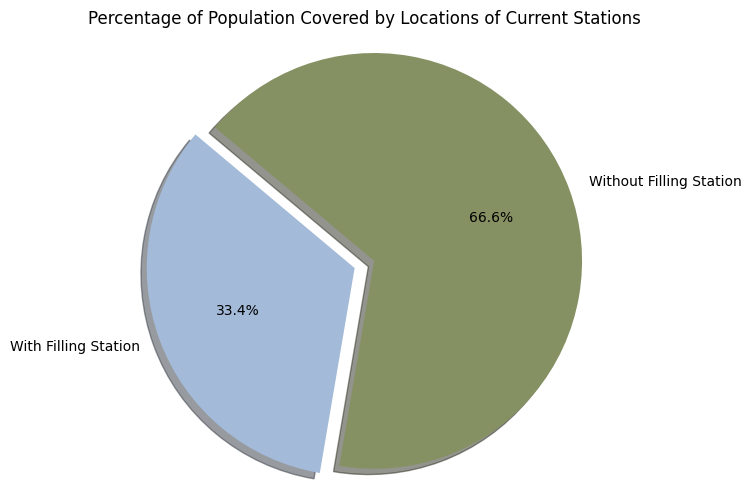

In [10]:
sum_density_for_non_inventory = total_avg_daily_density_cnt - sum_density_for_current_inventory

labels = 'With Filling Station', 'Without Filling Station'
sizes = [sum_density_for_current_inventory, sum_density_for_non_inventory]
colors = ['#a3bad8', '#859163']
explode = (0.1, 0)

# Plot
plt.figure(figsize=(8, 6))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)
plt.axis('equal')
plt.title('Percentage of Population Covered by Locations of Current Stations')
plt.show()

# **Initial exploration using distance to nearest station and foot traffic to find potential top 10 locations**
This is just for some initial data analysis into potential top locations!

In [11]:
filtered_data = distance_data[distance_data['full_address'].isin(addresses_of_top_40)]

# Sort the filtered DataFrame by 'distance_to_closest_station' in descending order to get the highest distances first
sorted_filtered_data = filtered_data.sort_values(by='distance_to_closest_station', ascending=False)

# Select the top 20 from this sorted list
top_20_from_40 = sorted_filtered_data.head(20)

# Now 'top_20_from_40' contains the top 20 addresses with the highest distance_to_closest_station values among your specified 40 addresses
# If you need to display these addresses along with their distances:
print("Top 20 Addresses with the Highest Distance Values:")
print(top_20_from_40[['full_address', 'distance_to_closest_station']])

Top 20 Addresses with the Highest Distance Values:
                 full_address  distance_to_closest_station
233       264-270 bay state 1                   410.942694
3             163-179 amory 1                   384.444074
303       1010 commonwealth 1                   362.899718
415             278 babcock f                   317.533416
92         949 commonwealth 1                   290.970980
387    30 harry agganis way p                   283.140791
313                10 buick 3                   257.066757
307                10 buick 1                   257.066757
426  675 - 725 commonwealth b                   253.382323
715  675 - 725 commonwealth 2                   253.382323
805  675 - 725 commonwealth 3                   253.382323
232  745 - 755 commonwealth 1                   184.388122
418  722-26-28 commonwealth b                   148.394943
298  722-26-28 commonwealth 1                   148.394943
299  722-26-28 commonwealth 4                   148.394943
300  

In [12]:
top_20_addresses = [
    "264-270 bay state 1",
    "163-179 amory 1",
    "1010 commonwealth 1",
    "278 babcock f",
    "949 commonwealth 1",
    "30 harry agganis way p",
    "10 buick 3",
    "10 buick 1",
    "675 - 725 commonwealth b",
    "675 - 725 commonwealth 2",
    "675 - 725 commonwealth 3",
    "745 - 755 commonwealth 1",
    "722-26-28 commonwealth b",
    "722-26-28 commonwealth 1",
    "722-26-28 commonwealth 4",
    "722-26-28 commonwealth 2",
    "722-26-28 commonwealth 3",
    "722-26-28 commonwealth 5",
    "64-86 cummington mall b",
    "930-940 commonwealth 2"
]


filtered_density = daily_avg_density[daily_avg_density['full_address'].isin(top_20_addresses)]

sorted_filtered_density = filtered_density.sort_values(by='avg_daily_density_cnt', ascending=False)

top_10_density_from_top_20 = sorted_filtered_density.head(10)

print("Top 10 Addresses with Highest avg_daily_density_cnt from the Top 20 by Distance:")
print(top_10_density_from_top_20[['full_address', 'avg_daily_density_cnt']])

Top 10 Addresses with Highest avg_daily_density_cnt from the Top 20 by Distance:
                  full_address  avg_daily_density_cnt
51         1010 commonwealth 1           30407.978984
217            163-179 amory 1           28306.317757
529     30 harry agganis way p           25303.564530
1141        949 commonwealth 1           20773.756354
893   722-26-28 commonwealth b           20158.773568
887   722-26-28 commonwealth 2           19013.473684
816    64-86 cummington mall b           18737.415929
905   745 - 755 commonwealth 1           17072.415859
9                   10 buick 1           16849.155867
888   722-26-28 commonwealth 3           15323.157895


In [13]:
sum_of_top_10_density = top_10_density_from_top_20['avg_daily_density_cnt'].sum()

total_sum_of_top_10_density = sum_of_top_10_density

print(f"Sum of the top 10 avg_daily_density_cnt values: {total_sum_of_top_10_density}")

Sum of the top 10 avg_daily_density_cnt values: 211946.0104279765


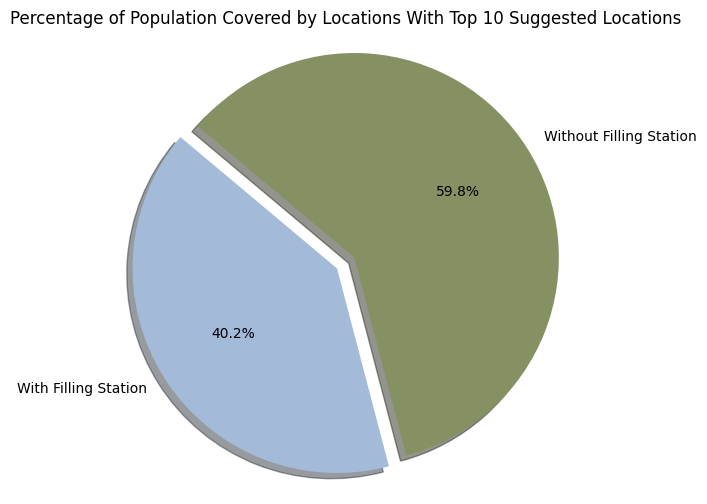

In [14]:
# if we were to install those 10 locations, how would the impact change?

sum_density_for_inventory_new = sum_density_for_current_inventory + total_sum_of_top_10_density

sum_density_for_non_inventory_new = total_avg_daily_density_cnt - sum_density_for_inventory_new

labels = 'With Filling Station', 'Without Filling Station'
sizes = [sum_density_for_inventory_new, sum_density_for_non_inventory_new]
colors = ['#a3bad8', '#859163']
explode = (0.1, 0)

# Plot
plt.figure(figsize=(8, 6))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)
plt.axis('equal')
plt.title('Percentage of Population Covered by Locations With Top 10 Suggested Locations')
plt.show()

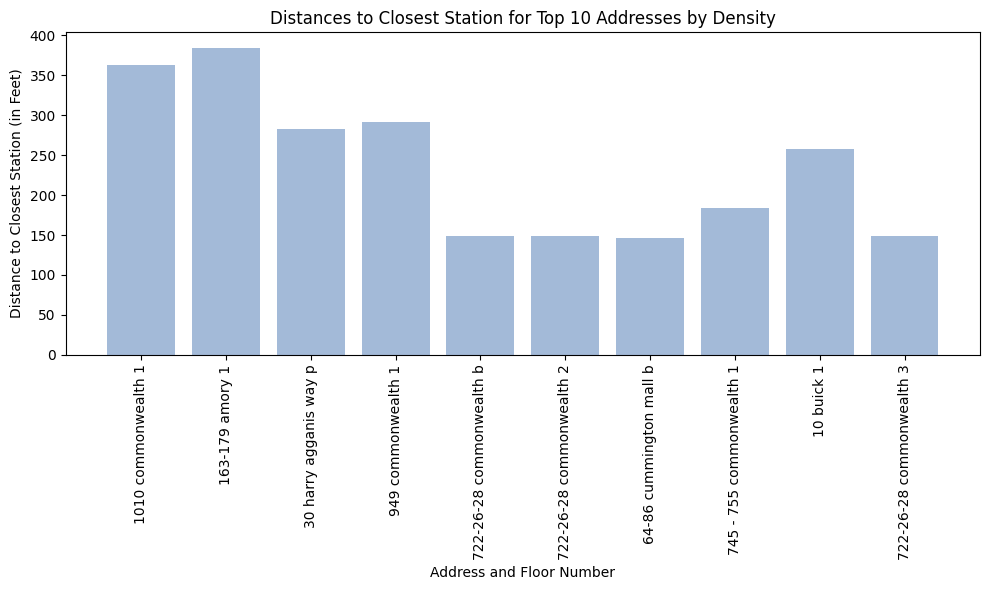

In [15]:
addresses_to_plot = top_10_density_from_top_20['full_address'].tolist()
filtered_distances = distance_data[distance_data['full_address'].isin(addresses_to_plot)]

filtered_distances_ordered = filtered_distances.set_index('full_address').reindex(index=addresses_to_plot).reset_index()

plt.figure(figsize=(10, 6))
plt.bar(filtered_distances_ordered['full_address'], filtered_distances_ordered['distance_to_closest_station'], color='#a3bad8')
plt.xlabel('Address and Floor Number')
plt.ylabel('Distance to Closest Station (in Feet)')
plt.title('Distances to Closest Station for Top 10 Addresses by Density')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# **Creating the data frame with every potential location and the factors for each location**

In [16]:
# creating the data frame that will be used to get the final outcome
final_outcome_df = final_df[['full_address', 'avg_daily_density_cnt', 'exists_in_inventory']]

# # creating a column with just the address, and just the floor
final_outcome_df[['address', 'floor']] = final_outcome_df['full_address'].str.rsplit(' ', n=1, expand=True)

# merging building type, and full address with the end of the address as well
density_data.drop_duplicates(subset='full_address', inplace=True)
final_outcome_df = pd.merge(final_outcome_df,
                            density_data[['full_address', 'building_desc', 'building_type']],
                            on='full_address',
                            how='left')
final_outcome_df = final_outcome_df.rename(columns={'building_desc': 'full_address_with_end'})

# merging distance data
final_outcome_df = pd.merge(final_outcome_df,
                            distance_data[['full_address', 'distance_to_closest_station']],
                            on='full_address',
                            how='left')

# merging AC data
final_outcome_df = pd.merge(final_outcome_df,
                            building_list[['address', 'Mechanical Ventilation']],
                            on='address',
                            how='left')

final_outcome_df.head()


,full_address,avg_daily_density_cnt,exists_in_inventory,address,floor,full_address_with_end,building_type,distance_to_closest_station,Mechanical Ventilation
0,1 buswell 1,298.986667,0,1 buswell,1,1 buswell street,Residential,415.533376,No
1,1 buswell 2,979.258065,0,1 buswell,2,1 buswell street,Residential,415.533376,No
2,1 buswell 3,369.287234,0,1 buswell,3,1 buswell street,Residential,415.533376,No
3,1 buswell 4,820.227462,0,1 buswell,4,1 buswell street,Residential,415.533376,No
4,1 buswell b,194.949495,0,1 buswell,b,1 buswell street,Residential,415.533376,No


In [17]:
# making and saving a copy of the original DataFrame to be used in the Extension Project
extension_df = final_outcome_df.copy()
extension_df.to_csv('/content/drive/MyDrive/ProjectCS506/BU Sustainability: Water Bottle stations/Team B/extension_data.csv', index=False)

# **Normalizing all of the data so that it can be used in weighted scoring**

In [18]:
from sklearn.preprocessing import MinMaxScaler

# Normalize the numerical data
scaler = MinMaxScaler()

final_outcome_df_normalized = final_outcome_df.copy()

# getting 1 and 0 for AC
final_outcome_df_normalized['Mechanical Ventilation'] = np.where(final_outcome_df_normalized['Mechanical Ventilation'] == 'No', 1, 0)

# Inverting exists_in_inventory since higher is worse
final_outcome_df_normalized['exists_in_inventory'] = 1 - scaler.fit_transform(final_outcome_df_normalized[['exists_in_inventory']])

# Normalize other factors
final_outcome_df_normalized['avg_daily_density_cnt'] = scaler.fit_transform(final_outcome_df_normalized[['avg_daily_density_cnt']])
final_outcome_df_normalized['distance_to_closest_station'] = scaler.fit_transform(final_outcome_df_normalized[['distance_to_closest_station']])

# these building scores have been tuned to yield the best and most optimal results for new locations to install water filling stations
# in the extension project, these are able to be modified by specific user inputs
building_scores = {
    'Residential': 0.9,
    'Academic': 1.0,
    'Administrative': 0.5,
    'Athletic': 0.8,
    'Student Support': 0.7,
    'Research': 0.4,
    'Parking': 0.0,
    'Commercial': 0.0
}
final_outcome_df_normalized['building_type_score'] = final_outcome_df_normalized['building_type'].map(building_scores)


In [19]:
final_outcome_df_normalized.head()

,full_address,avg_daily_density_cnt,exists_in_inventory,address,floor,full_address_with_end,building_type,distance_to_closest_station,Mechanical Ventilation,building_type_score
0,1 buswell 1,0.006724,1.0,1 buswell,1,1 buswell street,Residential,0.240095,1,0.9
1,1 buswell 2,0.024117,1.0,1 buswell,2,1 buswell street,Residential,0.240095,1,0.9
2,1 buswell 3,0.008521,1.0,1 buswell,3,1 buswell street,Residential,0.240095,1,0.9
3,1 buswell 4,0.020051,1.0,1 buswell,4,1 buswell street,Residential,0.240095,1,0.9
4,1 buswell b,0.004064,1.0,1 buswell,b,1 buswell street,Residential,0.240095,1,0.9


# **Applying the weighted scoring method to build final prioritized list**

In [20]:
# Define weights
# these have been tuned based off of how much they should impact locations to yield the best results
# the weights have been tuned to prioritize optimal locations for new water filling stations
weights = {
    'avg_daily_density_cnt': 0.4,
    'exists_in_inventory': 0.25,
    'building_type_score': 0.15,
    'distance_to_closest_station': 0.1,
    'Mechanical Ventilation': 0.1
}

# Calculate weighted score
final_outcome_df_normalized['score'] = (final_outcome_df_normalized['avg_daily_density_cnt'] * weights['avg_daily_density_cnt'] +
               final_outcome_df_normalized['exists_in_inventory'] * weights['exists_in_inventory'] +
               final_outcome_df_normalized['building_type_score'] * weights['building_type_score'] +
               final_outcome_df_normalized['distance_to_closest_station'] * weights['distance_to_closest_station'] +
               final_outcome_df_normalized['Mechanical Ventilation'] * weights['Mechanical Ventilation'])

# Merging the scores to the original data frame containing the original, non normalized data
final_outcome_df = final_outcome_df.merge(
    final_outcome_df_normalized[['full_address', 'score']],
    on='full_address',
    how='left'
)

# Sort DataFrame by score in descending order to prioritize higher scores
final_outcome_df_sorted = final_outcome_df.sort_values(by='score', ascending=False)

In [21]:
final_outcome_df_sorted.head()

,full_address,avg_daily_density_cnt,exists_in_inventory,address,floor,full_address_with_end,building_type,distance_to_closest_station,Mechanical Ventilation,score
1098,890 commonwealth 2,37461.345829,0,890 commonwealth,2,890 commonwealth avenue,Academic,0.000000,Yes,0.782750
51,1010 commonwealth 1,30407.978984,0,1010 commonwealth,1,1010 commonwealth avenue,Academic,362.899718,Yes,0.731583
529,30 harry agganis way p,25303.564530,0,30 harry agganis way,p,30 harry agganis way,Administrative,283.140791,No,0.699772
744,595 commonwealth 1,25045.567046,0,595 commonwealth,1,595 commonwealth avenue,Academic,0.000000,Yes,0.655773
217,163-179 amory 1,28306.317757,0,163-179 amory,1,163-179 amory street,Administrative,384.444074,Yes,0.636334


In [22]:
final_outcome_to_save = final_outcome_df_sorted[['full_address_with_end', 'floor']]

final_outcome_to_save.rename(columns={'full_address_with_end': 'address'}, inplace=True)

final_outcome_to_save.head()


<ipython-input-22-f78635f839b9>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_outcome_to_save.rename(columns={'full_address_with_end': 'address'}, inplace=True)


,address,floor
1098,890 commonwealth avenue,2
51,1010 commonwealth avenue,1
529,30 harry agganis way,p
744,595 commonwealth avenue,1
217,163-179 amory street,1


In [23]:
final_outcome_to_save.to_csv('/content/drive/MyDrive/ProjectCS506/BU Sustainability: Water Bottle stations/Team B/final_prioritized_list.csv', index=False)

# **Data analysis to find potential impact if our highest priority locations have a new water filling station installed**

In [24]:
# Select the top 30 rows
top_30_rows = final_outcome_df_sorted.head(30)

top_30_rows['full_address_with_end'] = top_30_rows['full_address_with_end'].str.title()

# Reset the index of the DataFrame and drop the original index
top_30_reset = top_30_rows[['full_address_with_end', 'floor']].reset_index(drop=True)

print('')
print(f'Top 30 Priority Locations To Install')
print('')
# Print each row with a custom row number starting from 1
for idx, row in enumerate(top_30_reset.itertuples(index=False), 1):
    print(f'{idx}. {row.full_address_with_end}, Floor {row.floor}')

print('')


Top 30 Priority Locations To Install

1. 890 Commonwealth Avenue, Floor 2
2. 1010 Commonwealth Avenue, Floor 1
3. 30 Harry Agganis Way, Floor p
4. 595 Commonwealth Avenue, Floor 1
5. 163-179 Amory Street, Floor 1
6. 264-270 Bay State Road, Floor 1
7. 949 Commonwealth Avenue, Floor 1
8. 700 Commonwealth Avenue, Floor b
9. 37-39 Carlton Street, Floor 2
10. 37-39 Carlton Street, Floor 4
11. 37-39 Carlton Street, Floor 3
12. 64-86 Cummington Mall, Floor b
13. 722-26-28 Commonwealth Avenue, Floor b
14. 37-39 Carlton Street, Floor b
15. 1053 Beacon Street, Floor 4
16. 1053 Beacon Street, Floor 3
17. 925 Commonwealth Avenue, Floor c
18. 722-26-28 Commonwealth Avenue, Floor 2
19. 1053 Beacon Street, Floor 2
20. 745 - 755 Commonwealth Avenue, Floor 1
21. 1053 Beacon Street, Floor 1
22. 1053 Beacon Street, Floor b
23. 514-522 Park Drive, Floor b
24. 10 Buick Street, Floor 1
25. 53 Bay State Road, Floor 3
26. 514-522 Park Drive, Floor 3
27. 27 Aberdeen Street, Floor 2
28. 25 Aberdeen Street, Flo

<ipython-input-24-382ef376ec13>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  top_30_rows['full_address_with_end'] = top_30_rows['full_address_with_end'].str.title()


In [25]:
# sum_density_for_current_inventory = the sum of the daily avg density count for the CURRENT inventory of stations
# total_avg_daily_density_cnt = sum of ALL daily avg density count


# Select the top 10 rows
top_10_rows = final_outcome_df_sorted.head(10)

# Calculate the sum of 'avg_daily_density_cnt' in these top 10 rows
sum_avg_daily_density_top_10 = top_10_rows['avg_daily_density_cnt'].sum()

# Printing the top 10 rows
print(top_10_rows[['full_address_with_end', 'floor']])

         full_address_with_end floor
1098   890 commonwealth avenue     2
51    1010 commonwealth avenue     1
529       30 harry agganis way     p
744    595 commonwealth avenue     1
217       163-179 amory street     1
453     264-270 bay state road     1
1141   949 commonwealth avenue     1
864    700 commonwealth avenue     b
579       37-39 carlton street     2
581       37-39 carlton street     4


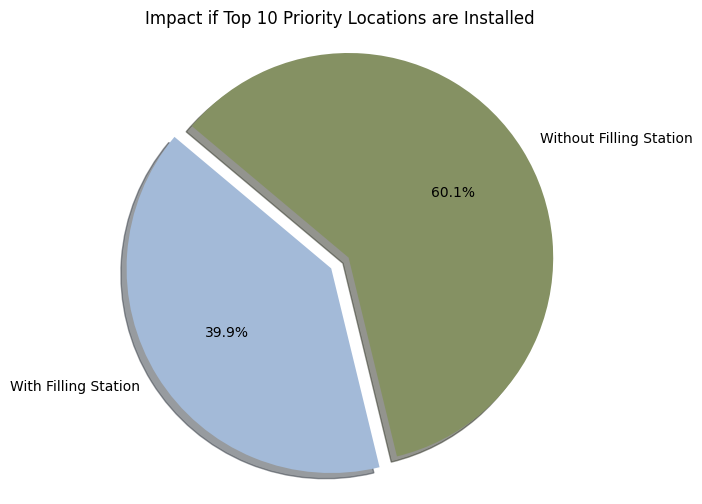

In [26]:
# if we were to install the top 10 locations, how would the impact change?

potential_total_sum_avg_daily_density_top_10 = sum_avg_daily_density_top_10 + sum_density_for_current_inventory

sum_density_for_non_inventory_new_10 = total_avg_daily_density_cnt - potential_total_sum_avg_daily_density_top_10

labels = 'With Filling Station', 'Without Filling Station'
sizes = [potential_total_sum_avg_daily_density_top_10, sum_density_for_non_inventory_new_10]
colors = ['#a3bad8', '#859163']
explode = (0.1, 0)

# Plot
plt.figure(figsize=(8, 6))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)
plt.axis('equal')
plt.title('Impact if Top 10 Priority Locations are Installed')
plt.show()

In [27]:
# Select the top 20 rows
top_20_rows = final_outcome_df_sorted.head(20)

# Calculate the sum of 'avg_daily_density_cnt' in these top 20 rows
sum_avg_daily_density_top_20 = top_20_rows['avg_daily_density_cnt'].sum()

# Printing the next 10 rows
last_10_rows_of_20 = top_20_rows.tail(10)
print(last_10_rows_of_20[['full_address_with_end', 'floor']])

              full_address_with_end floor
580            37-39 carlton street     3
816           64-86 cummington mall     b
893   722-26-28 commonwealth avenue     b
582            37-39 carlton street     b
65               1053 beacon street     4
64               1053 beacon street     3
1128        925 commonwealth avenue     c
887   722-26-28 commonwealth avenue     2
63               1053 beacon street     2
905   745 - 755 commonwealth avenue     1


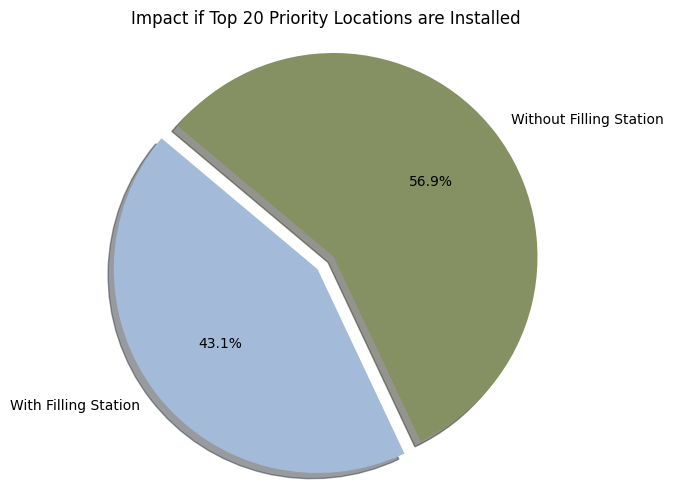

In [28]:
# if we were to install the top 20 locations, how would the impact change?

potential_total_sum_avg_daily_density_top_20 = sum_avg_daily_density_top_20 + sum_density_for_current_inventory

sum_density_for_non_inventory_new_20 = total_avg_daily_density_cnt - potential_total_sum_avg_daily_density_top_20

labels = 'With Filling Station', 'Without Filling Station'
sizes = [potential_total_sum_avg_daily_density_top_20, sum_density_for_non_inventory_new_20]
colors = ['#a3bad8', '#859163']
explode = (0.1, 0)

# Plot
plt.figure(figsize=(8, 6))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)
plt.axis('equal')
plt.title('Impact if Top 20 Priority Locations are Installed')
plt.show()

In [29]:
# Calculate the sum of 'avg_daily_density_cnt' in these top 30 rows
sum_avg_daily_density_top_30 = top_30_rows['avg_daily_density_cnt'].sum()

# Printing the next 10 rows
last_10_rows_of_30 = top_30_rows.tail(10)
print(last_10_rows_of_30[['full_address_with_end', 'floor']])

       full_address_with_end floor
62        1053 Beacon Street     1
66        1053 Beacon Street     b
693       514-522 Park Drive     b
9            10 Buick Street     1
704        53 Bay State Road     3
692       514-522 Park Drive     3
460       27 Aberdeen Street     2
449       25 Aberdeen Street     b
990  808 Commonwealth Avenue     4
629           455 Park Drive     3


In [32]:
print(sum_density_for_current_inventory)

1047536.127592127


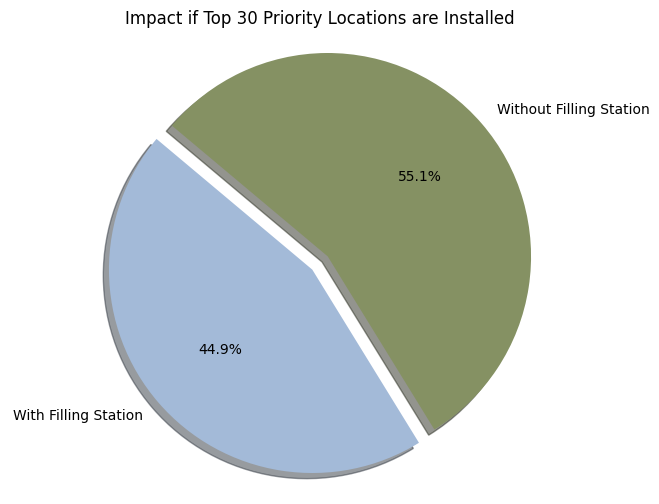

In [31]:
# if we were to install the top 30 locations, how would the impact change?

potential_total_sum_avg_daily_density_top_30 = sum_avg_daily_density_top_30 + sum_density_for_current_inventory

sum_density_for_non_inventory_new_30 = total_avg_daily_density_cnt - potential_total_sum_avg_daily_density_top_30

labels = 'With Filling Station', 'Without Filling Station'
sizes = [potential_total_sum_avg_daily_density_top_30, sum_density_for_non_inventory_new_30]
colors = ['#a3bad8', '#859163']
explode = (0.1, 0)

# Plot
plt.figure(figsize=(8, 6))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)
plt.axis('equal')
plt.title('Impact if Top 30 Priority Locations are Installed')
plt.show()